In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

# Point Python to your project's src directory
sys.path.append(str(Path("../src").resolve()))

In [3]:
import chess
import pandas as pd
import torch
import torch.nn as nn

In [4]:
planes = torch.zeros((12, 8, 8), dtype=torch.float32)
planes.shape

torch.Size([12, 8, 8])

In [5]:
planes.flatten().shape

torch.Size([768])

In [6]:
print(planes.shape)
print(planes.ndim)
print(planes.numel())

torch.Size([12, 8, 8])
3
768


In [7]:
planes[0, 6, 4] = 1

print(planes[0])

tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


In [8]:
torch.zeros(5)

tensor([0., 0., 0., 0., 0.])

In [9]:
def encode_board(board: chess.Board) -> torch.Tensor:
    planes = torch.zeros((12, 8, 8), dtype=torch.float32)

    for square, piece in board.piece_map().items():
        plane_index = PIECE_TO_PLANE[(piece.color, piece.piece_type)]

        row = 7 - chess.square_rank(square)
        col = chess.square_file(square)

        planes[plane_index, row, col] = 1.0

    flat = planes.flatten()
    # [white_to_move, white_K, white_Q, black_K, black_Q]
    features = torch.empty(5, dtype=torch.float32)
    features[0] = float(board.turn == chess.WHITE)
    features[1] = float(board.has_kingside_castling_rights(chess.WHITE))
    features[2] = float(board.has_queenside_castling_rights(chess.WHITE))
    features[3] = float(board.has_kingside_castling_rights(chess.BLACK))
    features[4] = float(board.has_queenside_castling_rights(chess.BLACK))

    result = torch.cat((flat, features))
    return result

In [10]:
PIECE_TO_PLANE = {
    (chess.WHITE, chess.PAWN): 0,
    (chess.WHITE, chess.KNIGHT): 1,
    (chess.WHITE, chess.BISHOP): 2,
    (chess.WHITE, chess.ROOK): 3,
    (chess.WHITE, chess.QUEEN): 4,
    (chess.WHITE, chess.KING): 5,
    (chess.BLACK, chess.PAWN): 6,
    (chess.BLACK, chess.KNIGHT): 7,
    (chess.BLACK, chess.BISHOP): 8,
    (chess.BLACK, chess.ROOK): 9,
    (chess.BLACK, chess.QUEEN): 10,
    (chess.BLACK, chess.KING): 11,
}

In [11]:
from neurachess.neural.encoding import encode_board

board = chess.Board()
x = encode_board(board)

print("Shape:", x.shape)
print("Pieces:", x[:768].sum().item())
print("Global features:", x[-5:])

Shape: torch.Size([773])
Pieces: 32.0
Global features: tensor([1., 1., 1., 1., 1.])


In [12]:
board.push_uci("e2e4")
x = encode_board(board)

print(x.shape)
print(x[-5:])

torch.Size([773])
tensor([0., 1., 1., 1., 1.])


In [13]:
df = pd.read_parquet("../data/chess_positions.parquet")
df.head()

,fen,cp,raw_cp,depth,eval_bucket,game_phase
0,rnb1kbnr/pp2pppp/3q4/8/8/2pQ4/PP2PPPP/R1B1KBNR...,-507,-507,22,strong_black,opening
1,rn1qkb1r/5ppp/b3pn2/2pp4/3PP3/2N3P1/PP3PBP/R1B...,-262,-262,21,moderate_black,opening
2,rnb1kb1r/ppppnp1p/6p1/4p1B1/4P3/2NP4/PqP2PPP/R...,32,32,20,equal,opening
3,r1bqk1nr/ppp2pp1/1bn1p2p/3pP3/1P1P4/P1N5/2P1NP...,161,161,21,moderate_white,opening
4,r1bq1rk1/ppp2ppp/3b4/8/2P5/5N1P/PP2PPP1/RNBQKB...,581,581,30,strong_white,opening


In [14]:
from neurachess.neural.dataset import ChessDataset

dataset = ChessDataset("../data/encoded")

print("Dataset size:", len(dataset))

x, y = dataset[0]

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Target evaluation:", y)
print("*")

Dataset size: 1000000
Input shape: torch.Size([773])
Target shape: torch.Size([1])
Target evaluation: tensor([-5.0700])
*


In [15]:
import torch
from torch.utils.data import DataLoader, random_split

from neurachess.neural.dataset import ChessDataset

dataset = ChessDataset("../data/encoded")

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [0.8, 0.1, 0.1],
    generator=torch.Generator().manual_seed(42),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)

In [16]:
from neurachess.neural.model import ChessEvaluator

model = ChessEvaluator(hidden_sizes=(256, 128))

loss_fn = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=0.01,
)

In [17]:
model.train()

total_loss = 0.0

for X_batch, y_batch in train_loader:
    optimizer.zero_grad()

    predictions = model(X_batch)

    loss = loss_fn(predictions, y_batch)

    loss.backward()
    optimizer.step()

    total_loss += loss.item() * X_batch.size(0)

train_loss = total_loss / len(train_loader.dataset)

print(f"Training MSE: {train_loss:.4f}")

Training MSE: 15.7248


In [18]:
model.eval()

total_val_loss = 0.0

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        
        predictions = model(X_batch)

        loss = loss_fn(predictions, y_batch)

        total_val_loss += loss.item() * X_batch.size(0)

val_loss = total_val_loss / len(val_loader.dataset)

print(f"Validation MSE: {val_loss:.4f}")

Validation MSE: 13.7449


In [30]:
import copy
from pathlib import Path

import torch

from neurachess.neural.model import ChessEvaluator
from neurachess.neural.train import train_one_epoch, validate

torch.manual_seed(42)

model = ChessEvaluator(
    input_size=773,
    hidden_sizes=(256, 128),
    dropout=0.1,
)

loss_fn = torch.nn.HuberLoss(delta=1.0)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=0.01,
)

EPOCHS = 20
SAVE_EVERY = None  # crash-safety backup to disk; set to None to disable

checkpoint_path = Path("../checkpoints/best_model.pt")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

history = {
    "train_mse": [],
    "val_mse": [],
    "train_mae_cp": [],
    "val_mae_cp": [],
    "gradients": [],
}

best_val_mse = float("inf")
best_state = None
best_epoch = 0
patience = 4
no_improvement = 0
track_gradients = False


def save_checkpoint(state, epoch, val_mse):
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": state,
            "val_mse": val_mse,
            "hidden_sizes": (256, 128),
            "input_size": 773,
        },
        checkpoint_path,
    )


for epoch in range(EPOCHS):
    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        loss_fn,
        log_every=100,
        track_gradients=track_gradients,
    )

    val_metrics = validate(
        model,
        val_loader,
        loss_fn,
    )

    history["train_mse"].append(train_metrics["mse"])
    history["val_mse"].append(val_metrics["mse"])
    history["train_mae_cp"].append(train_metrics["mae_cp"])
    history["val_mae_cp"].append(val_metrics["mae_cp"])
    if track_gradients:
        history["gradients"].append(train_metrics["gradients"])

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train MSE: {train_metrics['mse']:.4f} | "
        f"Val MSE: {val_metrics['mse']:.4f} | "
        f"Train MAE: {train_metrics['mae_cp']:.2f} cp | "
        f"Val MAE: {val_metrics['mae_cp']:.2f} cp"
    )

    # Keep the best weights in RAM only
    if val_metrics["mse"] < best_val_mse:
        best_val_mse = val_metrics["mse"]
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())
    else:
        no_improvement += 1

    if no_improvement >= patience:
        print("Early stopping")
        break

    # Occasional disk backup of the best weights so far
    if SAVE_EVERY and (epoch + 1) % SAVE_EVERY == 0 and best_state is not None:
        save_checkpoint(best_state, best_epoch, best_val_mse)

# Final save of the best weights
save_checkpoint(best_state, best_epoch, best_val_mse)

# Optional: load the best weights back into the model for evaluation/graphs
model.load_state_dict(best_state)

print(f"Best val MSE {best_val_mse:.4f} at epoch {best_epoch}")

Epoch 01/20 | Train MSE: 2.2773 | Val MSE: 2.0262 | Train MAE: 271.63 cp | Val MAE: 245.80 cp
Epoch 02/20 | Train MSE: 1.9352 | Val MSE: 1.8887 | Train MAE: 236.50 cp | Val MAE: 231.38 cp
Epoch 03/20 | Train MSE: 1.8312 | Val MSE: 1.8440 | Train MAE: 225.76 cp | Val MAE: 226.89 cp
Epoch 04/20 | Train MSE: 1.7621 | Val MSE: 1.7905 | Train MAE: 218.62 cp | Val MAE: 221.19 cp
Epoch 05/20 | Train MSE: 1.7108 | Val MSE: 1.7720 | Train MAE: 213.33 cp | Val MAE: 219.31 cp
Epoch 06/20 | Train MSE: 1.6725 | Val MSE: 1.7542 | Train MAE: 209.39 cp | Val MAE: 217.46 cp
Epoch 07/20 | Train MSE: 1.6394 | Val MSE: 1.7344 | Train MAE: 205.97 cp | Val MAE: 215.47 cp
Epoch 08/20 | Train MSE: 1.6104 | Val MSE: 1.7338 | Train MAE: 202.93 cp | Val MAE: 215.39 cp
Epoch 09/20 | Train MSE: 1.5879 | Val MSE: 1.7184 | Train MAE: 200.65 cp | Val MAE: 213.76 cp
Epoch 10/20 | Train MSE: 1.5692 | Val MSE: 1.7115 | Train MAE: 198.71 cp | Val MAE: 213.05 cp
Epoch 11/20 | Train MSE: 1.5508 | Val MSE: 1.7030 | Train MA

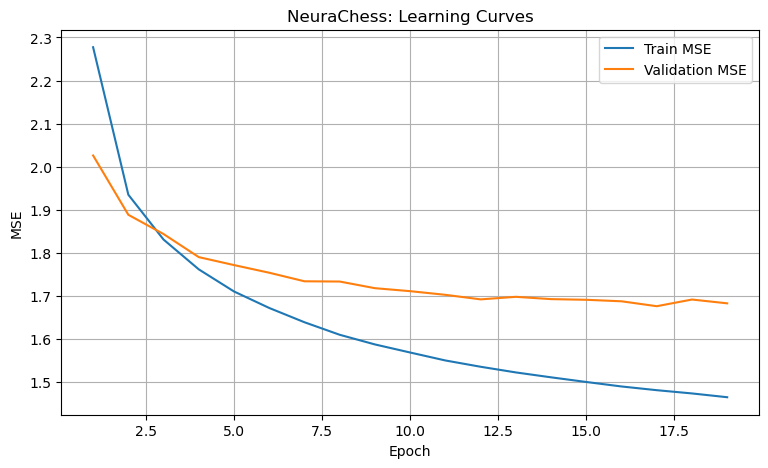

In [31]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_mse"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_mse"], label="Train MSE")
plt.plot(epochs, history["val_mse"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("NeuraChess: Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

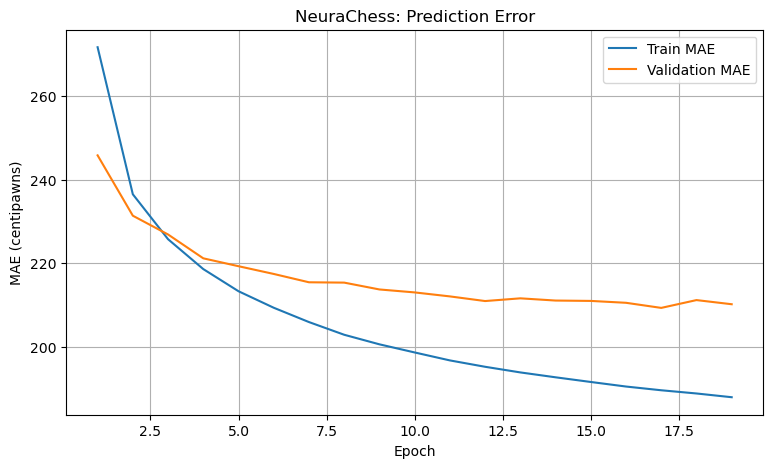

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_mae_cp"], label="Train MAE")
plt.plot(epochs, history["val_mae_cp"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE (centipawns)")
plt.title("NeuraChess: Prediction Error")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
checkpoint = torch.load(
    "../checkpoints/best_model.pt",
    weights_only=True,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

ChessEvaluator(
  (network): Sequential(
    (0): Linear(in_features=773, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [34]:
import numpy as np

predictions = []
actuals = []

with torch.no_grad():
    for X, y in val_loader:
        output = model(X)

        predictions.extend(output.flatten().tolist())
        actuals.extend(y.flatten().tolist())

predictions = np.array(predictions)
actuals = np.array(actuals)

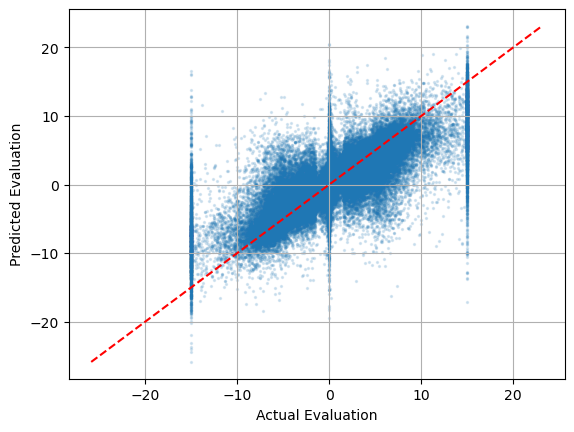

In [35]:
minimum = min(actuals.min(), predictions.min())
maximum = max(actuals.max(), predictions.max())

plt.scatter(actuals, predictions, s=2, alpha=0.15)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.xlabel("Actual Evaluation")
plt.ylabel("Predicted Evaluation")
plt.grid()
plt.show()

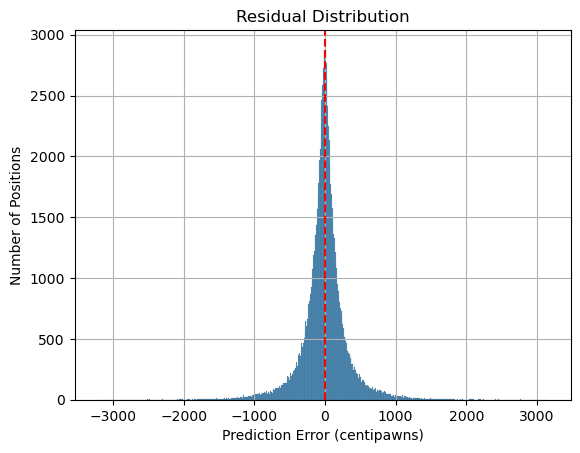

In [36]:
import seaborn as sns

errors = (predictions - actuals) * 100

sns.histplot(errors)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Prediction Error (centipawns)")
plt.ylabel("Number of Positions")
plt.title("Residual Distribution")
plt.grid()
plt.show()